# Análisis exploratorio de datos (EDA)

**Proyecto:** Predicción de la asistencia actual al nivel superior en jóvenes de 18 a 24 años con secundario completo (EPH – INDEC)
**Autora:** Liliana Elizabeth Iñigo · **Materia:** Aprendizaje Automático

Esta notebook explora el dataset construido en `1.0-lei-carga-y-construccion-dataset.ipynb` (`data/processed/eph_jovenes_asistencia_superior.csv`). El objetivo es conocer los datos antes de prepararlos:

1. Estructura general, tipos y faltantes
2. Distribución de las variables numéricas
3. Frecuencias de las variables categóricas (para detectar categorías poco frecuentes)
4. Relación de cada variable con la asistencia al nivel superior
5. Relación entre variables numéricas (dispersión y correlación)
6. Conclusiones: patrones observados e hipótesis

> Todas las relaciones que se describen son **asociaciones observadas en los datos**, no relaciones causales. Cuando se propone una explicación, se presenta como hipótesis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)

# Dataset con una fila por joven (salida de la notebook 1.0)
datos = pd.read_csv("../data/processed/eph_jovenes_asistencia_superior.csv")
OBJETIVO = "asiste_superior"
FIGURAS = "../reports/figures/"

# Etiquetas de los códigos de la EPH, para que tablas y gráficos se lean sin el diccionario
ETIQUETAS = {
    "sexo": {1: "Varón", 2: "Mujer"},
    "parentesco_jefe": {1: "Jefe/a", 2: "Cónyuge", 3: "Hijo/a", 4: "Yerno/nuera", 5: "Nieto/a",
                        6: "Madre/padre", 7: "Suegro/a", 8: "Hermano/a", 9: "Otro familiar", 10: "No familiar"},
    "estado_civil": {1: "Unido/a", 2: "Casado/a", 3: "Separado/a o divorciado/a", 4: "Viudo/a", 5: "Soltero/a", 9: "Ns/Nr"},
    "cobertura_salud": {1: "Obra social", 2: "Mutual/prepaga", 3: "Plan público", 4: "No paga ni le descuentan",
                        9: "Ns/Nr", 12: "Obra social + prepaga", 13: "Obra social + plan público", 23: "Prepaga + plan público"},
    "lugar_nacimiento": {1: "Esta localidad", 2: "Otra localidad de la provincia", 3: "Otra provincia",
                         4: "País limítrofe", 5: "Otro país", 9: "Ns/Nr"},
    "condicion_actividad": {0: "Sin entrevista individual", 1: "Ocupado/a", 2: "Desocupado/a", 3: "Inactivo/a"},
    "tipo_vivienda": {1: "Casa", 2: "Departamento", 3: "Pieza de inquilinato", 4: "Pieza en hotel/pensión",
                      5: "Local no construido para habitación", 6: "Otros"},
    "tenencia_vivienda": {0: "Sin dato", 1: "Propietario vivienda y terreno", 2: "Propietario solo vivienda", 3: "Inquilino",
                          4: "Ocupante por impuestos/expensas", 5: "Ocupante en relación de dependencia",
                          6: "Ocupante gratuito", 7: "Ocupante de hecho", 8: "En sucesión", 9: "Otra situación"},
    "jefe_nivel_educativo": {7: "Sin instrucción", 1: "Primaria incompleta", 2: "Primaria completa",
                             3: "Secundaria incompleta", 4: "Secundaria completa",
                             5: "Superior incompleto", 6: "Superior completo"},
    "jefe_sexo": {1: "Varón", 2: "Mujer"},
    "jefe_condicion_actividad": {0: "Sin entrevista individual", 1: "Ocupado/a", 2: "Desocupado/a", 3: "Inactivo/a"},
    "region": {1: "Gran Buenos Aires", 40: "Noroeste", 41: "Noreste", 42: "Cuyo", 43: "Pampeana", 44: "Patagonia"},
}

def con_etiquetas(columna):
    # Devuelve la columna con los códigos reemplazados por su significado (los vacíos quedan como "No aplica")
    return datos[columna].map(ETIQUETAS[columna]).fillna("No aplica (joven jefe/a o cónyuge)") \
        if columna.startswith("jefe_") else datos[columna].map(ETIQUETAS[columna])

datos.shape

(9665, 26)

## 1. Estructura general, tipos y faltantes

Se revisa el tipo de cada columna, la cantidad de valores distintos y los faltantes. Las columnas de identificación (`codusu`, `nro_hogar`, `componente`, `trimestre`) y el `ponderador` no describen al joven: no se analizan como predictoras.

In [2]:
resumen = pd.DataFrame({
    "tipo": datos.dtypes.astype(str),
    "valores distintos": datos.nunique(),
    "faltantes": datos.isna().sum(),
    "% faltantes": (datos.isna().mean() * 100).round(1),
})
resumen

,tipo,valores distintos,faltantes,% faltantes
codusu,str,7898,0,0.0
nro_hogar,int64,9,0,0.0
componente,int64,15,0,0.0
trimestre,str,4,0,0.0
ponderador,int64,2025,0,0.0
asiste_superior,int64,2,0,0.0
sexo,int64,2,0,0.0
edad,int64,7,0,0.0
parentesco_jefe,int64,8,0,0.0
es_jefe_o_conyuge,int64,2,0,0.0


In [3]:
# Control de calidad: cada persona debe aparecer una sola vez y las edades deben estar en el rango de la población
print("Personas repetidas:", datos.duplicated(["codusu", "nro_hogar", "componente"]).sum())
print("Rango de edad:", datos["edad"].min(), "a", datos["edad"].max())
print("Valores de la variable objetivo:", sorted(datos[OBJETIVO].unique()))

Personas repetidas: 0
Rango de edad: 18 a 24
Valores de la variable objetivo: [np.int64(0), np.int64(1)]


**Lectura:** no hay personas repetidas y las edades están dentro del rango definido (18 a 24). Los únicos faltantes son:

- `ingreso_resto_hogar_pc` (28,8 %): hogares que no respondieron ingresos.
- `jefe_nivel_educativo`, `jefe_sexo`, `jefe_condicion_actividad` (13,8 %): jóvenes que son jefe/a o cónyuge; no es un dato perdido sino un caso en que la variable **no aplica**.
- `personas_por_ambiente` (4 casos): hogares sin dato de ambientes.

Varias columnas están guardadas como números (`int64`) pero son **categóricas**: los números son códigos de la EPH, no cantidades. Se tratan como categorías en todo el análisis.

### Variable objetivo

In [4]:
# Frecuencia de la variable objetivo (sin ponderar y ponderada con el factor de expansión de la EPH)
frecuencia = datos[OBJETIVO].value_counts().sort_index()
print(pd.DataFrame({"personas": frecuencia, "%": (frecuencia / frecuencia.sum() * 100).round(1)},
                   ).rename(index={0: "0 · No asiste", 1: "1 · Asiste"}))
ponderada = np.average(datos[OBJETIVO], weights=datos["ponderador"])
print(f"\n% que asiste en la muestra: {datos[OBJETIVO].mean():.1%} · % ponderado (población que representa): {ponderada:.1%}")

                 personas     %
asiste_superior                
0 · No asiste        4366  45.2
1 · Asiste           5299  54.8

% que asiste en la muestra: 54.8% · % ponderado (población que representa): 53.2%


**Lectura:** las clases están equilibradas (55 % / 45 %). El porcentaje ponderado (53 %) es parecido al de la muestra: el análisis se hace **sin ponderar**, porque el interés está en los patrones entre casos y no en estimar totales de población.

## 2. Variables numéricas: distribución

Se usan **histogramas** para ver la forma de cada distribución (si es simétrica, si tiene una cola larga, dónde se concentran los casos) y **diagramas de caja** para detectar valores extremos.

In [5]:
numericas = ["edad", "personas_hogar", "menores_10_hogar", "personas_por_ambiente", "ingreso_resto_hogar_pc"]
datos[numericas].describe().round(2)

,edad,personas_hogar,menores_10_hogar,personas_por_ambiente,ingreso_resto_hogar_pc
count,9665.00,9665.00,9665.00,9661.00,6881.00
mean,21.15,4.00,0.27,1.36,600228.58
std,1.92,1.81,0.61,0.75,765067.39
min,18.00,1.00,0.00,0.05,0.00
25%,20.00,3.00,0.00,1.00,240000.00
50%,21.00,4.00,0.00,1.25,442383.17
75%,23.00,5.00,0.00,1.67,766666.67
max,24.00,18.00,7.00,15.00,23633333.33


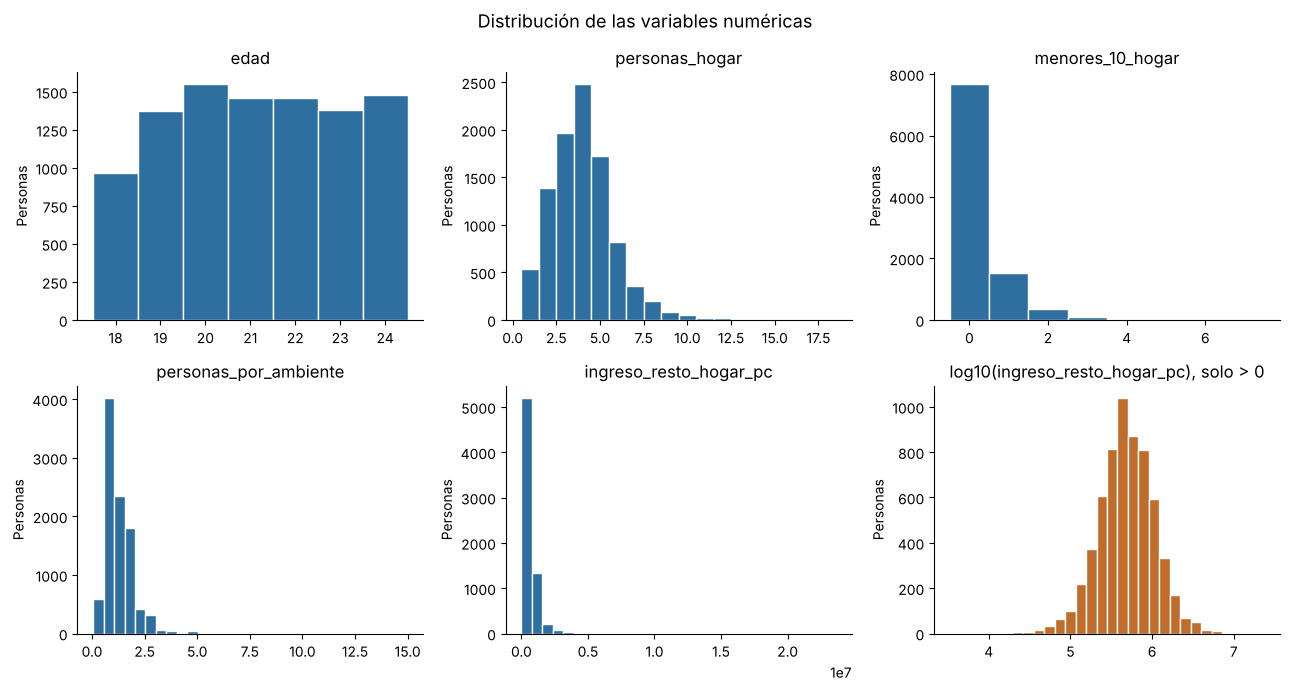

In [6]:
# Histogramas de las variables numéricas
fig, ejes = plt.subplots(2, 3, figsize=(13, 7))
ejes = ejes.ravel()
for eje, col in zip(ejes, numericas):
    valores = datos[col].dropna()
    # Las variables de conteo usan un intervalo por valor entero; las continuas, 30 intervalos
    bins = {"edad": np.arange(17.5, 25.5, 1), "personas_hogar": np.arange(0.5, 19.5, 1),
            "menores_10_hogar": np.arange(-0.5, 8.5, 1)}.get(col, 30)
    eje.hist(valores, bins=bins, color="#2f6f9f", edgecolor="white")
    eje.set_title(col)
    eje.set_ylabel("Personas")
    eje.spines[["top", "right"]].set_visible(False)
# Último panel: el ingreso en escala logarítmica, para ver mejor su forma
eje = ejes[-1]
eje.hist(np.log10(datos["ingreso_resto_hogar_pc"][datos["ingreso_resto_hogar_pc"] > 0]), bins=30,
         color="#c06c2b", edgecolor="white")
eje.set_title("log10(ingreso_resto_hogar_pc), solo > 0")
eje.set_ylabel("Personas")
eje.spines[["top", "right"]].set_visible(False)
plt.suptitle("Distribución de las variables numéricas", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURAS + "eda_histogramas_numericas.png", dpi=110)

Asimetría del ingreso: 12.2 (0 sería simétrico)
Casos por encima de 1,556,667 pesos: 360 (5.2% de los que tienen dato)


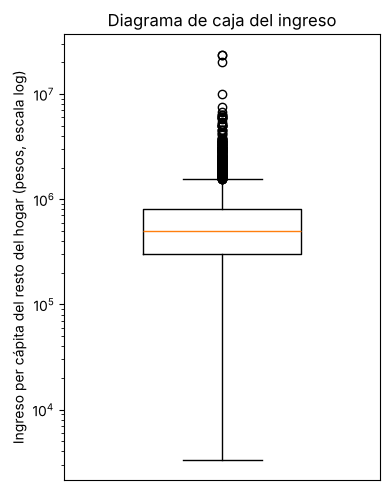

In [7]:
# Valores extremos del ingreso: regla del rango intercuartílico (1,5 × RIC)
ingreso = datos["ingreso_resto_hogar_pc"].dropna()
q1, q3 = ingreso.quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
print(f"Asimetría del ingreso: {ingreso.skew():.1f} (0 sería simétrico)")
print(f"Casos por encima de {limite:,.0f} pesos: {(ingreso > limite).sum()} ({(ingreso > limite).mean():.1%} de los que tienen dato)")

# Diagrama de caja (vertical) en escala logarítmica; se excluyen los ceros, que no tienen logaritmo
fig, eje = plt.subplots(figsize=(4, 5))
eje.boxplot(ingreso[ingreso > 0], widths=0.5)
eje.set_yscale("log")
eje.set_ylabel("Ingreso per cápita del resto del hogar (pesos, escala log)")
eje.set_xticks([])
eje.set_title("Diagrama de caja del ingreso")
plt.tight_layout()

**Lectura:**

- `edad` se reparte en forma pareja entre 18 y 24 años (con menos casos de 18, porque muchos todavía no terminaron el secundario).
- `personas_hogar`, `menores_10_hogar` y `personas_por_ambiente` son conteos o cocientes con **cola a la derecha**: la mayoría de los hogares tiene 3 a 5 personas y ningún menor de 10 años, y unos pocos hogares tienen valores altos.
- `ingreso_resto_hogar_pc` es la variable **más asimétrica** (asimetría ≈ 12): hay 360 casos por encima del límite de 1,5 × RIC. Son valores posibles (hogares de ingresos altos), no errores, así que **no se eliminan**. En escala logarítmica la distribución se vuelve mucho más simétrica: eso justifica aplicar una transformación logarítmica en el preprocesamiento.
- 675 jóvenes tienen ingreso del resto del hogar igual a 0. La mayoría vive solo (no hay "resto del hogar"); este caso se analiza en la sección 4.

## 3. Variables categóricas: tablas de frecuencia

Las **tablas de frecuencia** muestran cuántos casos hay en cada categoría. Sirven para detectar categorías con muy pocos casos, que aportan poca información y conviene agrupar antes de codificar.

In [8]:
categoricas = ["sexo", "parentesco_jefe", "estado_civil", "cobertura_salud", "lugar_nacimiento", "condicion_actividad",
               "tipo_vivienda", "tenencia_vivienda", "jefe_nivel_educativo", "jefe_sexo", "jefe_condicion_actividad", "region"]

for col in categoricas:
    tabla = con_etiquetas(col).value_counts()
    print(f"\n{col}")
    print(pd.DataFrame({"personas": tabla, "%": (tabla / len(datos) * 100).round(1)}).to_string())


sexo
       personas     %
sexo                 
Mujer      5052  52.3
Varón      4613  47.7

parentesco_jefe
                 personas     %
parentesco_jefe                
Hijo/a               6973  72.1
Jefe/a               1005  10.4
Nieto/a               602   6.2
Cónyuge               332   3.4
Hermano/a             248   2.6
Otro familiar         228   2.4
Yerno/nuera           178   1.8
No familiar            99   1.0

estado_civil
                           personas     %
estado_civil                             
Soltero/a                      8692  89.9
Unido/a                         861   8.9
Casado/a                         71   0.7
Separado/a o divorciado/a        37   0.4
Viudo/a                           3   0.0
Ns/Nr                             1   0.0

cobertura_salud
                            personas     %
cobertura_salud                           
Obra social                     5115  52.9
No paga ni le descuentan        3959  41.0
Mutual/prepaga                

In [9]:
# Categorías con menos de 50 casos: candidatas a agruparse en el preprocesamiento
poco_frecuentes = []
for col in categoricas:
    tabla = con_etiquetas(col).value_counts()
    for categoria, n in tabla[tabla < 50].items():
        poco_frecuentes.append({"variable": col, "categoría": categoria, "personas": n})
pd.DataFrame(poco_frecuentes)

,variable,categoría,personas
0,estado_civil,Separado/a o divorciado/a,37
1,estado_civil,Viudo/a,3
2,estado_civil,Ns/Nr,1
3,cobertura_salud,Ns/Nr,31
4,cobertura_salud,Prepaga + plan público,3
5,cobertura_salud,Obra social + plan público,2
6,lugar_nacimiento,Ns/Nr,6
7,condicion_actividad,Sin entrevista individual,23
8,tipo_vivienda,Pieza de inquilinato,19
9,tipo_vivienda,Pieza en hotel/pensión,5


**Lectura:** varias variables tienen categorías con muy pocos casos (por ejemplo, tipos de vivienda distintos de casa o departamento, combinaciones de cobertura de salud o respuestas "Ns/Nr"). Con tan pocos casos no se puede aprender nada confiable sobre ellas, por eso en el preprocesamiento se **agrupan** en categorías más amplias y con sentido (ver notebook 3.0). Las respuestas "Ns/Nr" y "Sin entrevista individual" se tratan como faltantes.

## 4. Relación de cada variable con la asistencia al nivel superior

Para cada variable se calcula el **porcentaje de jóvenes que asiste** en cada categoría o tramo. La línea punteada marca el promedio general (54,8 %): las barras que se alejan de ella señalan grupos con asistencia mayor o menor que el promedio.

In [10]:
promedio = datos[OBJETIVO].mean() * 100

def grafico_asistencia(serie, titulo, eje, orden=None):
    # Barras horizontales con el % que asiste por categoría y la cantidad de casos
    tabla = datos.groupby(serie)[OBJETIVO].agg(["mean", "size"])
    tabla = tabla.loc[orden] if orden is not None else tabla.sort_values("mean")
    eje.barh(tabla.index.astype(str), tabla["mean"] * 100, color="#2f6f9f")
    eje.axvline(promedio, color="#555555", linestyle="--", linewidth=1)
    for i, (pct, n) in enumerate(zip(tabla["mean"] * 100, tabla["size"])):
        eje.text(pct + 1, i, f"{pct:.0f}% (n={n:,})", va="center", fontsize=8)
    eje.set_xlim(0, 105)
    eje.set_title(titulo, fontsize=10)
    eje.set_xlabel("% que asiste")
    eje.spines[["top", "right"]].set_visible(False)
    return tabla

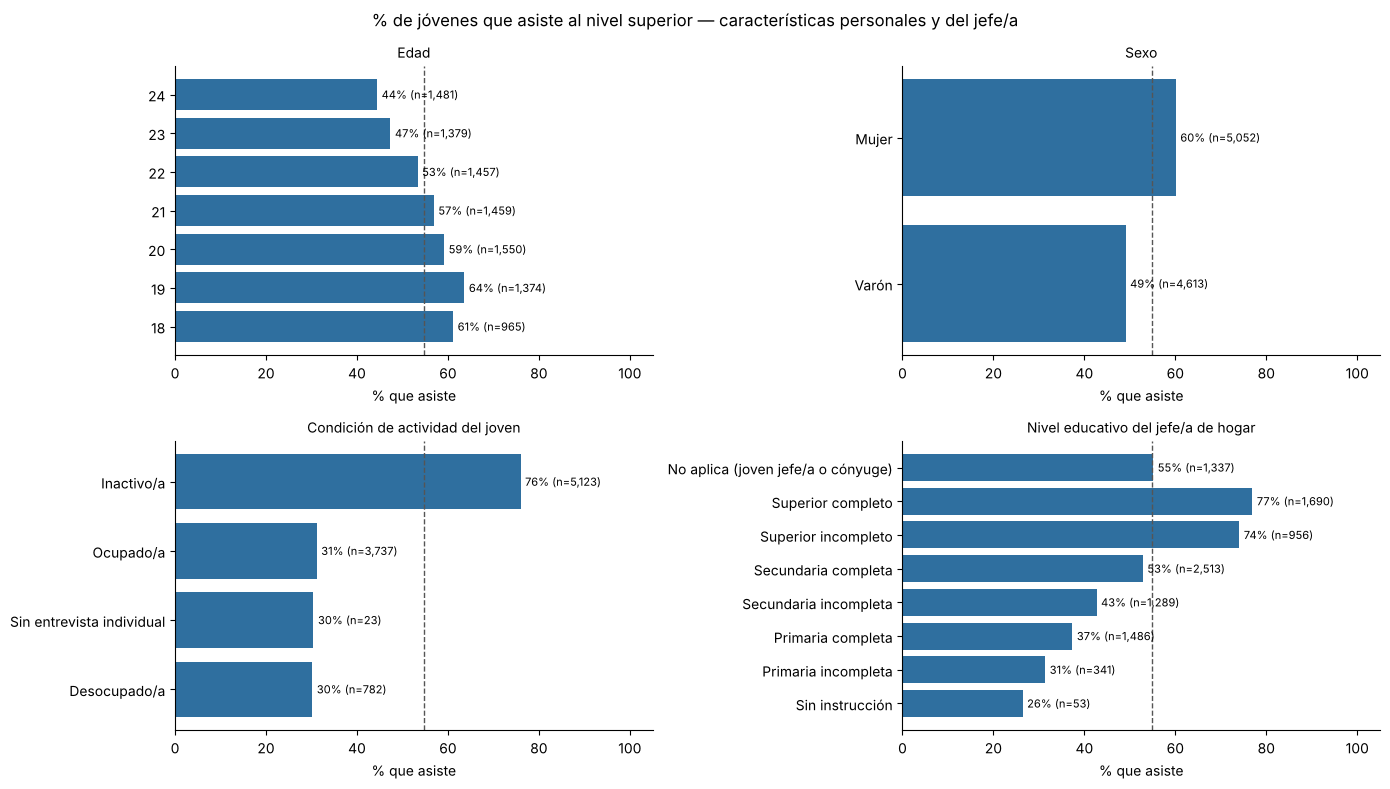

In [11]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
grafico_asistencia(datos["edad"], "Edad", ejes[0, 0], orden=list(range(18, 25)))
grafico_asistencia(con_etiquetas("sexo"), "Sexo", ejes[0, 1])
grafico_asistencia(con_etiquetas("condicion_actividad"), "Condición de actividad del joven", ejes[1, 0])
grafico_asistencia(con_etiquetas("jefe_nivel_educativo"), "Nivel educativo del jefe/a de hogar", ejes[1, 1],
                   orden=["Sin instrucción", "Primaria incompleta", "Primaria completa", "Secundaria incompleta",
                          "Secundaria completa", "Superior incompleto", "Superior completo",
                          "No aplica (joven jefe/a o cónyuge)"])
plt.suptitle("% de jóvenes que asiste al nivel superior — características personales y del jefe/a", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURAS + "eda_asistencia_personales.png", dpi=110)

**Lectura:**

- **Edad:** la asistencia baja con la edad, de alrededor de 61–64 % a los 18–19 años a 44 % a los 24.
- **Sexo:** las mujeres asisten más que los varones (60 % frente a 49 %).
- **Condición de actividad:** los inactivos asisten mucho más (76 %) que los ocupados y desocupados (alrededor de 30 %). Esta es la variable "zona gris" señalada en el planteo: se mide al mismo tiempo que la asistencia y en parte puede ser **consecuencia** de estudiar (quien estudia muchas veces no busca trabajo), no solo causa.
- **Nivel educativo del jefe/a:** es la relación más ordenada: la asistencia sube de 26–31 % cuando el jefe/a no tiene instrucción o no terminó la primaria a 74–77 % cuando tiene estudios superiores. Es coherente con lo planteado en el contexto del proyecto sobre el "clima educativo" del hogar.

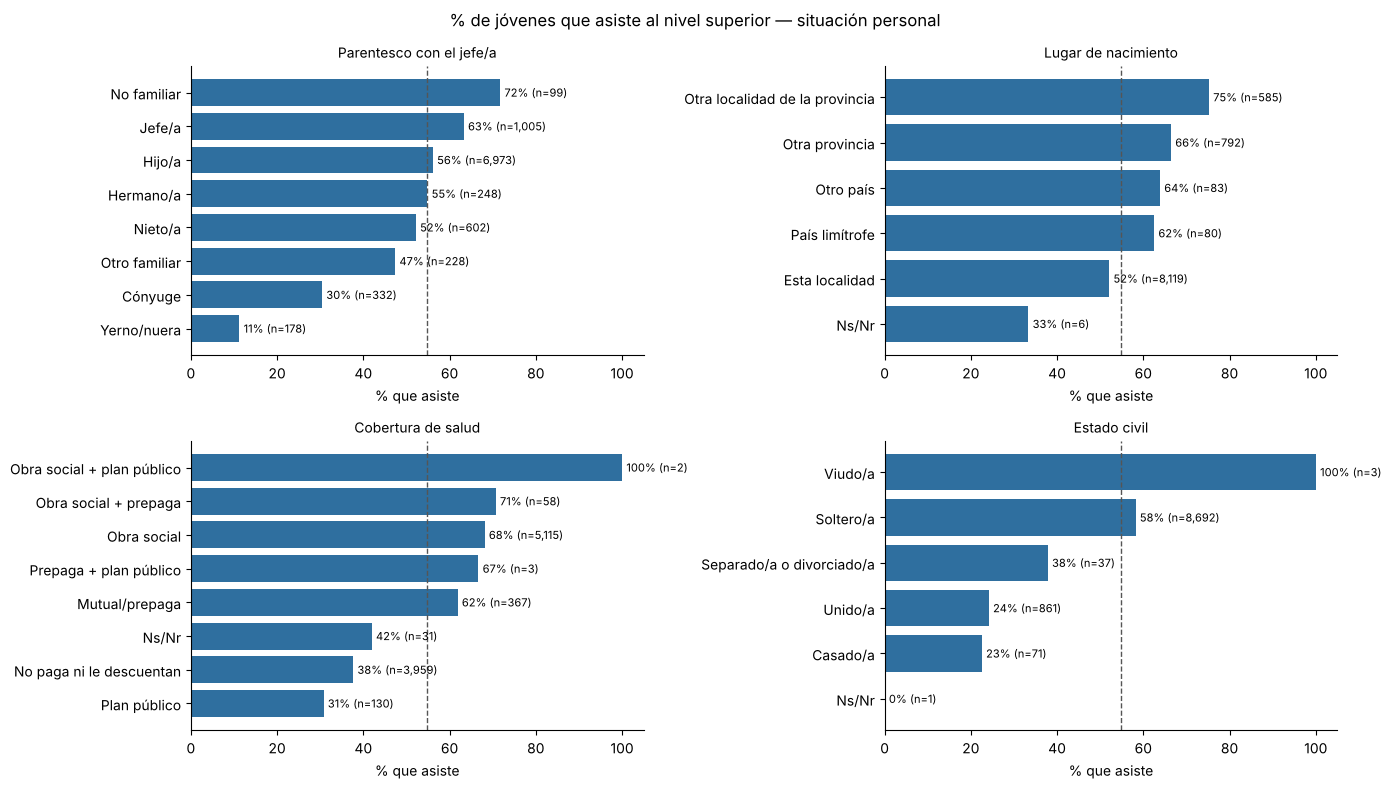

In [12]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
grafico_asistencia(con_etiquetas("parentesco_jefe"), "Parentesco con el jefe/a", ejes[0, 0])
grafico_asistencia(con_etiquetas("lugar_nacimiento"), "Lugar de nacimiento", ejes[0, 1])
grafico_asistencia(con_etiquetas("cobertura_salud"), "Cobertura de salud", ejes[1, 0])
grafico_asistencia(con_etiquetas("estado_civil"), "Estado civil", ejes[1, 1])
plt.suptitle("% de jóvenes que asiste al nivel superior — situación personal", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURAS + "eda_asistencia_situacion.png", dpi=110)

**Lectura:**

- **Parentesco:** los jóvenes que son **jefes de su propio hogar** asisten más que el promedio (63 %), mientras que los cónyuges (30 %) y los yernos/nueras (11 %) asisten mucho menos. El **estado civil** muestra lo mismo: unidos/as y casados/as asisten cerca del 23–24 %, frente al 58 % de los solteros/as.
- **Lugar de nacimiento:** quienes nacieron en otra localidad de la provincia (75 %) o en otra provincia (66 %) asisten más que quienes nacieron en la misma localidad (52 %).
- **Cobertura de salud:** con obra social o prepaga la asistencia ronda el 62–71 %; sin cobertura o con plan público, 31–38 %. La cobertura funciona como un indicador indirecto de la situación económica y laboral del hogar.

**Hipótesis (no comprobadas con estos datos):** los jóvenes que viven solos como jefes de hogar o que nacieron en otra localidad podrían ser, en parte, jóvenes que **se mudaron para estudiar** a una ciudad con oferta universitaria. Si fuera así, esas variables reflejarían en parte la decisión de estudiar, igual que la condición de actividad. Se dejan señaladas para tenerlas en cuenta al interpretar resultados.

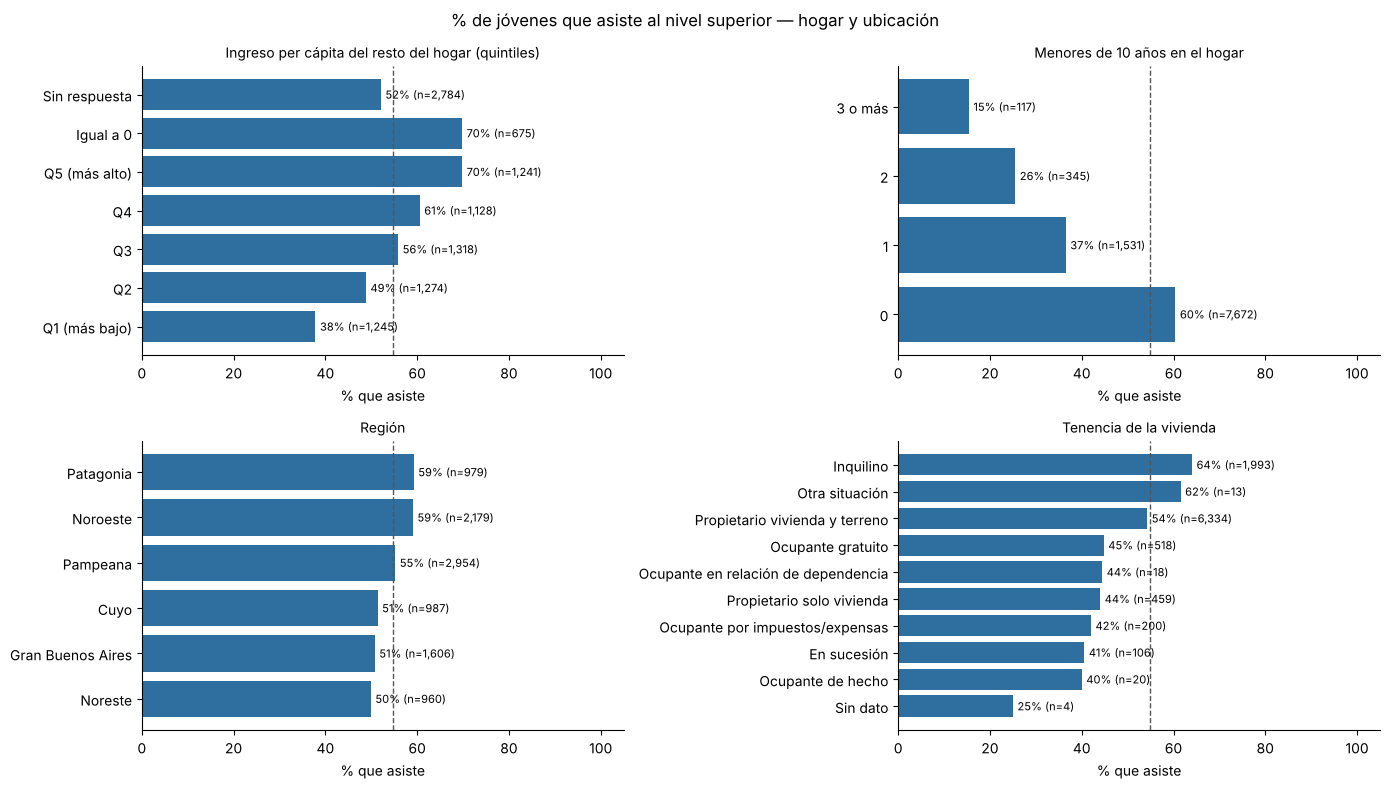

In [13]:
datos["tramo_ingreso"] = pd.qcut(datos["ingreso_resto_hogar_pc"].where(datos["ingreso_resto_hogar_pc"] > 0), 5,
                                 labels=["Q1 (más bajo)", "Q2", "Q3", "Q4", "Q5 (más alto)"]).astype(str)
# Primero los hogares sin respuesta; después los de ingreso igual a 0 (jóvenes que viven solos o cuyo resto del
# hogar no tiene ingresos): para quien vive solo el 0 es un dato cierto aunque el hogar no haya respondido
datos.loc[datos["ingresos_sin_respuesta"] == 1, "tramo_ingreso"] = "Sin respuesta"
datos.loc[datos["ingreso_resto_hogar_pc"] == 0, "tramo_ingreso"] = "Igual a 0"

datos["menores_10_tramo"] = datos["menores_10_hogar"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3 o más"})

fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
grafico_asistencia(datos["tramo_ingreso"], "Ingreso per cápita del resto del hogar (quintiles)", ejes[0, 0],
                   orden=["Q1 (más bajo)", "Q2", "Q3", "Q4", "Q5 (más alto)", "Igual a 0", "Sin respuesta"])
grafico_asistencia(datos["menores_10_tramo"], "Menores de 10 años en el hogar", ejes[0, 1], orden=["0", "1", "2", "3 o más"])
grafico_asistencia(con_etiquetas("region"), "Región", ejes[1, 0])
grafico_asistencia(con_etiquetas("tenencia_vivienda"), "Tenencia de la vivienda", ejes[1, 1])
plt.suptitle("% de jóvenes que asiste al nivel superior — hogar y ubicación", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURAS + "eda_asistencia_hogar.png", dpi=110)

In [14]:
# ¿Quiénes tienen ingreso del resto del hogar igual a 0?
cero = datos[datos["ingreso_resto_hogar_pc"] == 0]
print(f"Jóvenes con ingreso del resto del hogar = 0: {len(cero)}")
print(f"  de ellos viven solos (hogar de 1 persona): {(cero['personas_hogar'] == 1).sum()}")
print(f"  % que asiste: {cero[OBJETIVO].mean():.1%}")

# ¿El faltante de ingresos se relaciona con la respuesta?
print("\n% que asiste según si el hogar respondió ingresos:")
print(datos.groupby(datos["ingresos_sin_respuesta"].map({0: "Respondió", 1: "No respondió"}))[OBJETIVO].mean().round(3))

Jóvenes con ingreso del resto del hogar = 0: 675
  de ellos viven solos (hogar de 1 persona): 540
  % que asiste: 69.8%

% que asiste según si el hogar respondió ingresos:
ingresos_sin_respuesta
No respondió    0.527
Respondió       0.557
Name: asiste_superior, dtype: float64


**Lectura:**

- **Ingreso:** la asistencia **crece con el ingreso del resto del hogar**, de 38 % en el quintil más bajo a 70 % en el más alto.
- Los jóvenes con ingreso del resto del hogar **igual a 0** asisten mucho (70 %): en su gran mayoría viven solos, por lo que el 0 no indica pobreza sino que no hay otros miembros. Es otra señal a favor de la hipótesis de los jóvenes que se mudan para estudiar. En la preparación se mantiene `personas_hogar`, que permite distinguir este caso.
- **Faltantes de ingreso:** quienes no respondieron ingresos asisten un poco menos (52,7 % frente a 55,7 %). La diferencia es chica, pero indica que el faltante no es totalmente al azar: por eso se conserva el indicador `ingresos_sin_respuesta` además de imputar el valor.
- **Menores de 10 años en el hogar:** cuantos más niños pequeños hay, menor es la asistencia (60 % sin menores, 37 % con uno, 26 % con dos).
- **Región:** las diferencias son moderadas (50–59 %); Noroeste y Patagonia tienen la asistencia más alta y Noreste y Gran Buenos Aires la más baja.
- **Tenencia:** los inquilinos asisten más (64 %) que los propietarios (54 %), lo que vuelve a ser compatible con jóvenes que alquilan para estudiar.

## 5. Relación entre variables numéricas

### Diagrama de dispersión

Se grafica el ingreso per cápita del resto del hogar (en escala logarítmica) contra las personas por ambiente, con un color para cada clase. Sirve para ver si las dos clases ocupan zonas distintas del plano o si están mezcladas. Se usa una muestra de 2.000 jóvenes para que los puntos no se tapen.

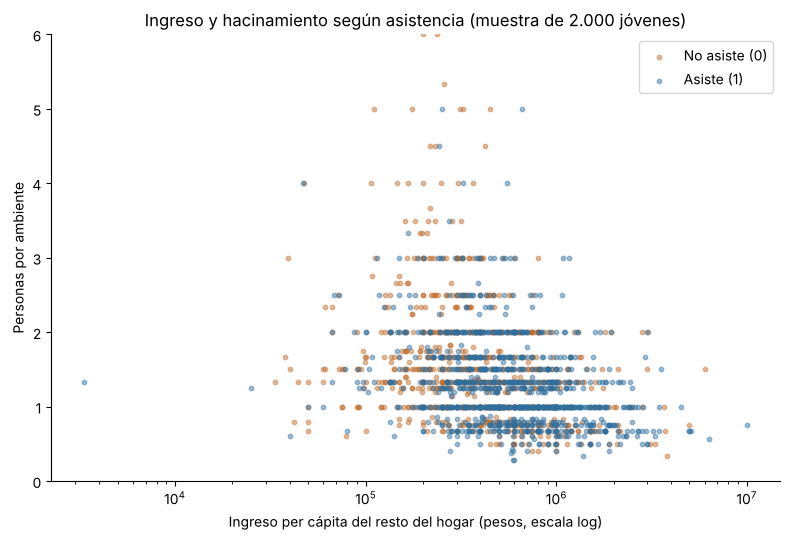

In [15]:
muestra = datos.dropna(subset=["ingreso_resto_hogar_pc", "personas_por_ambiente"])
muestra = muestra[muestra["ingreso_resto_hogar_pc"] > 0].sample(2000, random_state=42)

fig, eje = plt.subplots(figsize=(8, 5.5))
for clase, color, nombre in [(0, "#c06c2b", "No asiste (0)"), (1, "#2f6f9f", "Asiste (1)")]:
    sub = muestra[muestra[OBJETIVO] == clase]
    eje.scatter(sub["ingreso_resto_hogar_pc"], sub["personas_por_ambiente"], s=10, alpha=0.45, color=color, label=nombre)
eje.set_xscale("log")
eje.set_xlabel("Ingreso per cápita del resto del hogar (pesos, escala log)")
eje.set_ylabel("Personas por ambiente")
eje.set_ylim(0, 6)
eje.legend()
eje.set_title("Ingreso y hacinamiento según asistencia (muestra de 2.000 jóvenes)")
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURAS + "eda_dispersion_ingreso_hacinamiento.png", dpi=110)

**Lectura:** los puntos de las dos clases están **muy mezclados**: no hay una frontera simple que las separe con estas dos variables. Se observa una tendencia (más puntos azules hacia la derecha, con ingresos más altos, y hacia abajo, con menos hacinamiento), pero ninguna variable alcanza sola para distinguir las clases. Es esperable en un fenómeno social con muchos factores, y anticipa que la tarea de clasificación no será trivial.

### Correlación entre variables numéricas

La matriz de correlación muestra si dos variables numéricas varían juntas. Sirve para detectar **redundancia**: dos variables muy correlacionadas aportan casi la misma información.

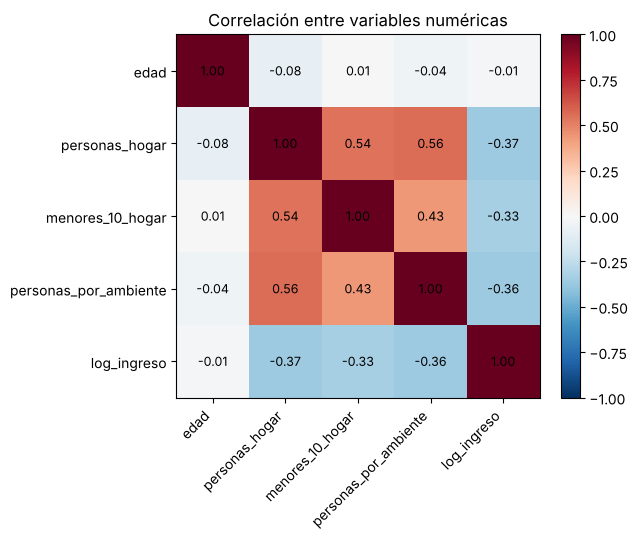

,edad,personas_hogar,menores_10_hogar,personas_por_ambiente,log_ingreso
edad,1.00,-0.08,0.01,-0.04,-0.01
personas_hogar,-0.08,1.00,0.54,0.56,-0.37
menores_10_hogar,0.01,0.54,1.00,0.43,-0.33
personas_por_ambiente,-0.04,0.56,0.43,1.00,-0.36
log_ingreso,-0.01,-0.37,-0.33,-0.36,1.00


In [16]:
# El ingreso se usa en logaritmo (solo valores > 0) para que los extremos no dominen la correlación
log_ingreso = np.log10(datos["ingreso_resto_hogar_pc"].where(datos["ingreso_resto_hogar_pc"] > 0))
correlacion = datos[numericas].assign(log_ingreso=log_ingreso).drop(columns="ingreso_resto_hogar_pc").corr()

fig, eje = plt.subplots(figsize=(6.5, 5.5))
imagen = eje.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_xticks(range(len(correlacion)))
eje.set_xticklabels(correlacion.columns, rotation=45, ha="right")
eje.set_yticks(range(len(correlacion)))
eje.set_yticklabels(correlacion.columns)
for i in range(len(correlacion)):
    for j in range(len(correlacion)):
        eje.text(j, i, f"{correlacion.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(imagen, fraction=0.046)
eje.set_title("Correlación entre variables numéricas")
plt.tight_layout()
plt.savefig(FIGURAS + "eda_correlacion_numericas.png", dpi=110)
correlacion.round(2)

**Lectura:** las correlaciones más altas son entre `personas_hogar` y `personas_por_ambiente` (0,56) y entre `personas_hogar` y `menores_10_hogar` (0,54): las tres dependen del tamaño del hogar. El ingreso per cápita (en logaritmo) es más bajo en hogares más numerosos y más hacinados (alrededor de −0,35), lo que es esperable porque se divide entre más personas. Ninguna correlación es tan alta como para que una variable repita a otra, así que **se conservan todas**.

## 6. Conclusiones del análisis exploratorio

**Calidad de los datos**
- No hay personas repetidas ni valores fuera de rango.
- Los faltantes están concentrados en el ingreso (28,8 %) y en los datos del jefe/a (13,8 %, casos en que no aplica). El faltante de ingreso se relaciona levemente con la respuesta, por lo que se conserva su indicador.
- Varias variables son categóricas codificadas con números y tienen categorías con muy pocos casos: hay que agruparlas y codificarlas sin inventar un orden.
- El ingreso es muy asimétrico y tiene valores extremos válidos: conviene transformarlo (logaritmo) antes de escalar.

**Patrones observados (asociaciones, no causas)**
- La asistencia es mayor en jóvenes más chicos, mujeres, solteros, sin niños pequeños en el hogar, con cobertura de salud contributiva, con mayor ingreso en el hogar y, sobre todo, cuando el jefe/a tiene estudios superiores.
- Las diferencias por región son moderadas.
- Ninguna variable separa sola las dos clases: la clasificación necesitará combinar varias.

**Hipótesis y cuidados para la interpretación**
- La **condición de actividad**, ser **jefe de hogar joven**, **vivir solo**, ser **inquilino** o haber **nacido en otra localidad** se asocian con más asistencia, pero podrían reflejar en parte la propia decisión de estudiar (por ejemplo, mudarse o dejar de trabajar para estudiar). Se conservan como variables, señaladas como "zona gris".

Estas conclusiones orientan las decisiones de la notebook `3.0-lei-preprocesamiento.ipynb`.